# Segmentación de clientes con K-means

## Introducción

Este proyecto estudia el comportamiento de compra de los clientes de una tienda online británica utilizando el conjunto de datos Online Retail.

Construiremos variables por cliente y aplicaremos K-means para explorar grupos con características de compra similares.

## Objetivo

Identificar y describir segmentos de clientes a partir de tres características:

- Recencia: días transcurridos desde la última compra hasta una fecha de referencia.
- Frecuencia: número de facturas de compra distintas durante el período.
- Importe: suma de los importes de las líneas de venta seleccionadas.

Estas características forman una representación conocida como RFM.

## Preguntas del análisis

- ¿Cómo se distribuyen la recencia, la frecuencia y el importe entre los clientes?
- ¿Qué número de grupos ofrece una segmentación interpretable y una separación razonable?
- ¿Qué características distinguen a cada segmento?
- ¿Qué tan estables son los grupos al cambiar la inicialización del algoritmo?

## Alcance

Trabajaremos con clientes identificados y líneas de productos con cantidades y precios positivos. Excluiremos cancelaciones y conceptos identificados como envíos, comisiones, ajustes y vales.

El importe representará ventas positivas antes de posibles cancelaciones posteriores. No corresponde al gasto neto final del cliente ni a su rentabilidad.

Los segmentos describirán patrones dentro del período observado. No representan categorías definitivas ni predicen por sí solos el comportamiento futuro.

## Metodología

Prepararemos las variables RFM, examinaremos sus distribuciones y evaluaremos transformaciones y escalado antes de aplicar K-means.

Compararemos distintos números de grupos mediante inercia, coeficiente de silueta e interpretación de los perfiles. Utilizaremos PCA para visualizar la segmentación en dos dimensiones e indicaremos cuánta variabilidad conserva esa representación.

## Fuente de los datos

Chen, D. (2015). Online Retail. UCI Machine Learning Repository.
https://doi.org/10.24432/C5BW33

El archivo `Online Retail.xlsx` debe estar en la misma carpeta que este notebook.

## 1. Carga y revisión inicial

Cargamos el archivo original y revisamos su estructura, los valores faltantes y el período disponible.

Leemos los códigos de factura y producto como texto. Representamos el identificador de cliente como un entero que admite valores faltantes.

En esta etapa no eliminamos registros. Primero cuantificamos los datos disponibles para documentar las decisiones de preparación.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Path("figures").mkdir(exist_ok=True)

datos_originales = pd.read_excel(
    "Online Retail.xlsx",
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
        "CustomerID": "Int64"
    }
)

datos = datos_originales.copy()

print("Número de registros:", len(datos))
print("Número de columnas:", datos.shape[1])

display(datos.head())

resumen = pd.DataFrame({
    "Tipo de dato": datos.dtypes.astype(str),
    "Valores faltantes": datos.isna().sum(),
    "Porcentaje faltante": (datos.isna().mean() * 100).round(2)
})

display(resumen)

print("Primera fecha:", datos["InvoiceDate"].min())
print("Última fecha:", datos["InvoiceDate"].max())
print("Clientes identificados distintos:", datos["CustomerID"].nunique())
print("Filas exactamente repetidas:", datos.duplicated().sum())

Número de registros: 541909
Número de columnas: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


,Tipo de dato,Valores faltantes,Porcentaje faltante
InvoiceNo,string,0,0.00
StockCode,string,0,0.00
Description,object,1454,0.27
Quantity,int64,0,0.00
InvoiceDate,datetime64[ns],0,0.00
UnitPrice,float64,0,0.00
CustomerID,Int64,135080,24.93
Country,object,0,0.00


Primera fecha: 2010-12-01 08:26:00
Última fecha: 2011-12-09 12:50:00
Clientes identificados distintos: 4372
Filas exactamente repetidas: 5268


## 2. Selección de ventas con cliente identificado

Seleccionamos líneas con cliente identificado, cantidad positiva y precio positivo. Excluimos facturas de cancelación y códigos identificados como envíos, comisiones, descuentos, ajustes, operaciones manuales, muestras y vales de regalo.

Normalizamos los códigos de factura y producto eliminando espacios externos y convirtiendo las letras a mayúsculas.

Conservamos las filas exactamente repetidas porque no contamos con un identificador de línea que permita confirmar errores. Esta decisión puede afectar el importe acumulado, aunque contar facturas distintas evita que las líneas repetidas aumenten la frecuencia de compra.

El importe calculado representa ventas positivas anteriores a posibles cancelaciones posteriores. Una compra cancelada después puede permanecer en esta selección; tendremos en cuenta esta limitación al interpretar los segmentos.

In [2]:
datos["InvoiceNo"] = datos["InvoiceNo"].str.strip().str.upper()
datos["StockCode"] = datos["StockCode"].str.strip().str.upper()

conceptos_excluidos = [
    "AMAZONFEE", "B", "BANK CHARGES", "C2", "CRUK",
    "D", "DOT", "M", "POST", "S"
]

es_cancelacion = datos["InvoiceNo"].str.startswith("C", na=False)
es_concepto_excluido = datos["StockCode"].isin(conceptos_excluidos)
es_vale = datos["StockCode"].str.startswith("GIFT_", na=False)

seleccion = (
    datos["CustomerID"].notna()
    & (datos["Quantity"] > 0)
    & (datos["UnitPrice"] > 0)
    & ~es_cancelacion
    & ~es_concepto_excluido
    & ~es_vale
)

ventas = datos.loc[seleccion].copy()
ventas["Importe"] = ventas["Quantity"] * ventas["UnitPrice"]

print("Registros originales:", len(datos))
print("Líneas de venta seleccionadas:", len(ventas))
print("Registros excluidos:", len(datos) - len(ventas))
print("Clientes seleccionados:", ventas["CustomerID"].nunique())
print("Facturas de venta distintas:", ventas["InvoiceNo"].nunique())

display(ventas.head())

Registros originales: 541909
Líneas de venta seleccionadas: 396340
Registros excluidos: 145569
Clientes seleccionados: 4334
Facturas de venta distintas: 18402


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Importe
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 3. Comprobación de las facturas seleccionadas

Antes de construir las variables por cliente, comprobamos que cada factura seleccionada esté asociada a un único cliente.

También verificamos que todas las ventas tengan fecha, ya que la recencia requiere conocer cuándo ocurrió la última compra.

Si aparecen facturas con varios clientes o fechas faltantes, revisaremos esos registros antes de continuar.

In [3]:
clientes_por_factura = ventas.groupby("InvoiceNo")["CustomerID"].nunique()
facturas_inconsistentes = clientes_por_factura[clientes_por_factura > 1]

print("Facturas con más de un cliente:", len(facturas_inconsistentes))
print("Líneas sin fecha:", ventas["InvoiceDate"].isna().sum())
print("Importes no positivos:", (ventas["Importe"] <= 0).sum())

display(facturas_inconsistentes.to_frame("Clientes_distintos"))

Facturas con más de un cliente: 0
Líneas sin fecha: 0
Importes no positivos: 0


,Clientes_distintos
InvoiceNo,


### Resultado de la selección

La selección contiene 396.340 líneas de venta correspondientes a 18.402 facturas y 4.334 clientes identificados.

No encontramos facturas asociadas a más de un cliente, fechas faltantes ni importes no positivos.

Estos registros permiten construir una tabla con una fila por cliente.

## 4. Construcción de las variables RFM

Calculamos tres características para cada cliente:

- Recencia: días desde su última compra hasta la fecha de referencia. Un valor menor indica una compra más reciente.
- Frecuencia: número de facturas de venta distintas dentro del período.
- Importe: suma de los importes de las líneas seleccionadas.

Utilizamos como referencia el 10 de diciembre de 2011, el día siguiente a la última fecha del archivo original. Calculamos la recencia por días calendario, sin considerar la hora de compra.

La frecuencia cuenta facturas, no productos ni líneas. El importe acumula ventas positivas y no descuenta cancelaciones posteriores.

Estas variables describen la actividad observada. Los clientes que aparecen cerca del final del período tienen menos tiempo para acumular compras, lo que puede influir en la segmentación.

In [4]:
# Tomamos el día siguiente al cierre del archivo como referencia.
fecha_referencia = (
    datos_originales["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

resumen_clientes = ventas.groupby("CustomerID").agg(
    Ultima_compra=("InvoiceDate", "max"),
    Frecuencia=("InvoiceNo", "nunique"),
    Importe=("Importe", "sum")
)

resumen_clientes["Recencia"] = (
    fecha_referencia - resumen_clientes["Ultima_compra"].dt.normalize()
).dt.days

rfm = resumen_clientes[["Recencia", "Frecuencia", "Importe"]].copy()
rfm.index.name = "Cliente"

print("Fecha de referencia:", fecha_referencia.date())
print("Número de clientes:", len(rfm))

display(rfm.head().round(2))

print("¿Coincide el total de facturas?",
      rfm["Frecuencia"].sum() == ventas["InvoiceNo"].nunique())

print("¿Coincide el importe total?",
      np.isclose(rfm["Importe"].sum(), ventas["Importe"].sum()))

print("Valores faltantes en RFM:", rfm.isna().sum().sum())

Fecha de referencia: 2011-12-10
Número de clientes: 4334


,Recencia,Frecuencia,Importe
Cliente,,,
12346,326,1,77183.60
12347,3,7,4310.00
12348,76,4,1437.24
12349,19,1,1457.55
12350,311,1,294.40


¿Coincide el total de facturas? True
¿Coincide el importe total? True
Valores faltantes en RFM: 0


## 5. Distribución de las variables RFM

Revisamos las escalas y la dispersión de las variables antes de aplicar K-means.

La recencia se expresa en días, la frecuencia en número de facturas y el importe en libras esterlinas. Estas diferencias de unidad y magnitud pueden influir en las distancias que utiliza el algoritmo.

Comparamos medias, medianas, percentiles y máximos para detectar distribuciones asimétricas y valores extremos. Esta revisión orientará las decisiones de transformación y escalado.

In [5]:
estadisticas_rfm = rfm.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

display(estadisticas_rfm.round(2))

print("Clientes con una sola factura:", (rfm["Frecuencia"] == 1).sum())

print("\nClientes con mayor importe acumulado:")
display(rfm.nlargest(10, "Importe").round(2))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Recencia,4334.0,93.23,100.18,1.00,18.00,51.00,143.00,264.00,312.00,369.00,374.00
Frecuencia,4334.0,4.25,7.63,1.00,1.00,2.00,5.00,9.00,13.00,30.00,206.00
Importe,4334.0,2021.47,8907.50,3.75,305.56,668.12,1631.62,3589.29,5745.56,18715.31,279138.02


Clientes con una sola factura: 1505

Clientes con mayor importe acumulado:


,Recencia,Frecuencia,Importe
Cliente,,,
14646,2,72,279138.02
18102,1,60,259657.30
17450,9,46,194550.79
16446,1,2,168472.50
14911,2,198,136275.72
12415,25,20,124564.53
14156,10,54,116729.63
17511,3,31,91062.38
12346,326,1,77183.60


### Interpretación de las variables RFM

La mediana de recencia es de 51 días y la mediana de frecuencia es de dos facturas. Hay 1.505 clientes con una sola factura de venta seleccionada.

El importe mediano por cliente es de £668,12, mientras que la media alcanza £2.021,47. El máximo es de £279.138,02. Esta diferencia muestra una distribución con una cola hacia importes elevados.

La frecuencia también presenta valores extremos: el 99 % de los clientes tiene hasta 30 facturas, aproximadamente, mientras que el máximo alcanza 206.

Estos valores no demuestran por sí solos que existan errores. Mantendremos los clientes y examinaremos una transformación que reduzca la influencia de las diferencias de magnitud.

El importe acumula ventas positivas sin descontar cancelaciones posteriores. Por ello, un importe alto no basta para identificar a un cliente de alto valor económico.

## 6. Visualización y transformación de las variables

Comparamos las distribuciones originales con una transformación logarítmica mediante log(1 + x).

Esta transformación comprime las diferencias entre valores grandes y conserva el orden de los valores dentro de cada variable. No elimina clientes ni corrige compras canceladas.

Aplicamos la transformación a recencia, frecuencia e importe. Las variables originales se conservan para interpretar posteriormente los segmentos en días, facturas y libras esterlinas.

La transformación cambia las distancias entre clientes y, por tanto, puede cambiar la segmentación. No garantiza distribuciones normales ni grupos bien separados.

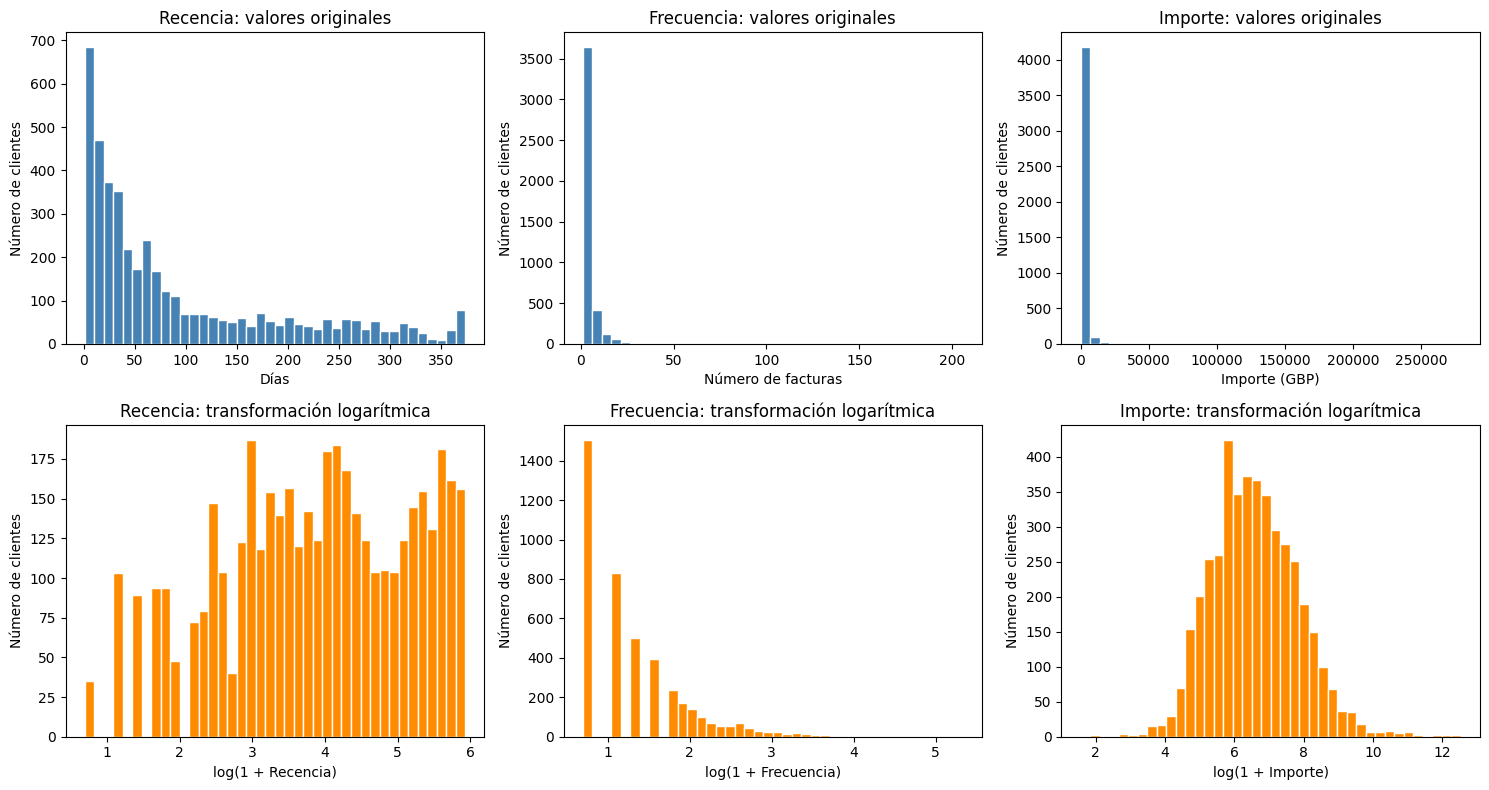

,Original,Transformación logarítmica
Recencia,1.24,-0.33
Frecuencia,11.95,1.21
Importe,19.56,0.40


In [6]:
variables = ["Recencia", "Frecuencia", "Importe"]
unidades = ["Días", "Número de facturas", "Importe (GBP)"]

rfm_log = np.log1p(rfm[variables])

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))

for i, variable in enumerate(variables):
    ejes[0, i].hist(
        rfm[variable], bins=40, color="steelblue", edgecolor="white"
    )
    ejes[0, i].set_title(f"{variable}: valores originales")
    ejes[0, i].set_xlabel(unidades[i])
    ejes[0, i].set_ylabel("Número de clientes")

    ejes[1, i].hist(
        rfm_log[variable], bins=40, color="darkorange", edgecolor="white"
    )
    ejes[1, i].set_title(f"{variable}: transformación logarítmica")
    ejes[1, i].set_xlabel(f"log(1 + {variable})")
    ejes[1, i].set_ylabel("Número de clientes")

plt.tight_layout()
fig.savefig("figures/distribuciones_rfm.png", dpi=160, bbox_inches="tight")
plt.show()

comparacion_asimetria = pd.DataFrame({
    "Original": rfm[variables].skew(),
    "Transformación logarítmica": rfm_log.skew()
})

display(comparacion_asimetria.round(2))

### Interpretación de la transformación

La transformación logarítmica reduce la asimetría del importe de 19,56 a 0,40 y la de frecuencia de 11,95 a 1,21. La recencia pasa de 1,24 a −0,33.

Los valores elevados quedan más próximos al resto sin eliminar clientes. La frecuencia conserva concentraciones en determinados valores porque es una variable discreta y muchos clientes tienen pocas facturas.

Utilizaremos las variables transformadas para construir la segmentación. Esta elección reduce el peso de las diferencias absolutas más grandes, pero no demuestra que existan grupos naturales ni garantiza una distribución normal.

Conservamos las variables originales para describir los segmentos en unidades interpretables.

## 7. Estandarización de las variables

Después de la transformación logarítmica, estandarizamos cada variable restando su media y dividiendo por su desviación estándar.

Esto produce variables con media aproximadamente cero y desviación estándar uno. Así evitamos que una variable domine las distancias únicamente por tener una escala numérica mayor.

El escalado no elimina valores extremos ni modifica la asimetría. Tampoco elimina las correlaciones entre variables.

Ajustamos el escalador sobre los clientes del período porque este análisis es exploratorio. Si posteriormente asignamos clientes nuevos, debemos aplicar la misma transformación y el escalador ya ajustado.

In [7]:
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()

rfm_escalado = pd.DataFrame(
    escalador.fit_transform(rfm_log),
    index=rfm_log.index,
    columns=rfm_log.columns
)

display(rfm_escalado.head().round(3))

# Usamos la misma definición de desviación estándar que el escalador.
revision_escalado = pd.DataFrame({
    "Media": rfm_escalado.mean(),
    "Desviación estándar": rfm_escalado.std(ddof=0),
    "Mínimo": rfm_escalado.min(),
    "Máximo": rfm_escalado.max()
})

display(revision_escalado.round(3))

print("Clientes preparados:", len(rfm_escalado))
print("¿Todos los valores son finitos?",
      np.isfinite(rfm_escalado.to_numpy()).all())

,Recencia,Frecuencia,Importe
Cliente,,,
12346,1.477,-0.951,3.727
12347,-1.891,1.082,1.426
12348,0.371,0.393,0.551
12349,-0.660,-0.951,0.562
12350,1.441,-0.951,-0.711


,Media,Desviación estándar,Mínimo,Máximo
Recencia,-0.0,1.0,-2.421,1.582
Frecuencia,0.0,1.0,-0.951,5.855
Importe,-0.0,1.0,-4.005,4.752


Clientes preparados: 4334
¿Todos los valores son finitos? True


## 8. Comparación del número de grupos

Ajustamos K-means con distintos valores de k, el número de grupos, utilizando las tres variables RFM transformadas y estandarizadas.

Evaluamos dos medidas:

- Inercia: suma de las distancias cuadradas de cada cliente al centro de su grupo. Disminuye al aumentar el número de grupos; buscamos si existe un punto a partir del cual la mejora se reduce.
- Coeficiente de silueta: compara la cercanía de un cliente a su propio grupo con la cercanía al grupo alternativo más próximo. Sus valores van de −1 a 1. Valores mayores indican grupos más compactos y separados según las distancias utilizadas.

Calculamos la inercia para k entre 1 y 8, y la silueta desde k = 2, porque esta última requiere más de un grupo.

Para cada valor de k utilizamos 20 inicializaciones y conservamos la solución con menor inercia. Fijamos una semilla para facilitar la reproducción.

La elección final considerará las métricas, el tamaño de los grupos y la interpretación de sus perfiles. K-means produce una partición incluso cuando los datos no contienen grupos claramente separados.

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
modelos = {}

for k in range(1, 9):
    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    etiquetas = modelo.fit_predict(rfm_escalado)
    modelos[k] = modelo

    silueta = np.nan

    if k > 1:
        silueta = silhouette_score(rfm_escalado, etiquetas)

    tamanos = pd.Series(etiquetas).value_counts()

    resultados.append({
        "k": k,
        "Inercia": modelo.inertia_,
        "Silueta": silueta,
        "Grupo_menor": tamanos.min(),
        "Grupo_mayor": tamanos.max()
    })

    print(f"Evaluación terminada para k = {k}")

evaluacion_k = pd.DataFrame(resultados)

display(evaluacion_k.round(3))

Evaluación terminada para k = 1
Evaluación terminada para k = 2
Evaluación terminada para k = 3
Evaluación terminada para k = 4
Evaluación terminada para k = 5
Evaluación terminada para k = 6
Evaluación terminada para k = 7
Evaluación terminada para k = 8


,k,Inercia,Silueta,Grupo_menor,Grupo_mayor
0,1,13002.000,NaN,4334,4334
1,2,6467.467,0.433,1661,2673
2,3,4848.440,0.338,752,1873
3,4,3918.578,0.334,716,1555
4,5,3261.748,0.318,355,1147
5,6,2835.986,0.313,344,954
6,7,2528.080,0.304,194,873
7,8,2323.692,0.301,215,848


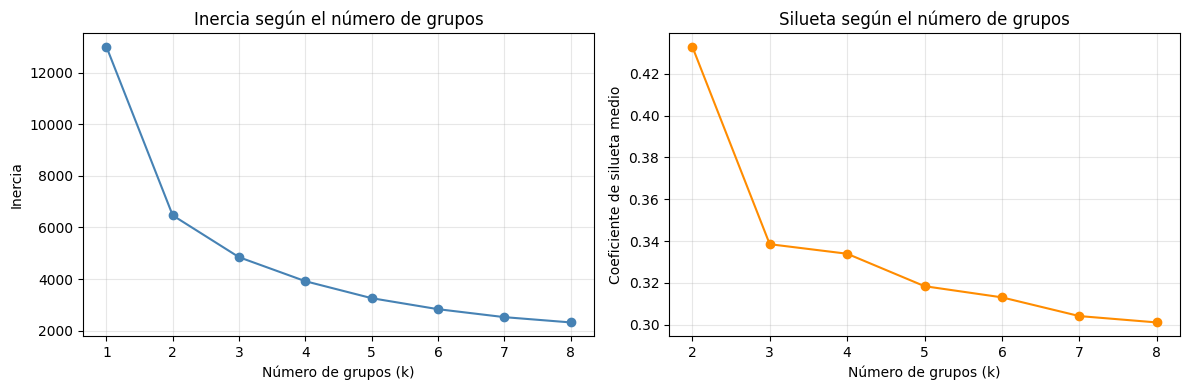

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].plot(
    evaluacion_k["k"],
    evaluacion_k["Inercia"],
    marker="o",
    color="steelblue"
)
ejes[0].set_title("Inercia según el número de grupos")
ejes[0].set_xlabel("Número de grupos (k)")
ejes[0].set_ylabel("Inercia")
ejes[0].set_xticks(evaluacion_k["k"])
ejes[0].grid(alpha=0.3)

ejes[1].plot(
    evaluacion_k["k"],
    evaluacion_k["Silueta"],
    marker="o",
    color="darkorange"
)
ejes[1].set_title("Silueta según el número de grupos")
ejes[1].set_xlabel("Número de grupos (k)")
ejes[1].set_ylabel("Coeficiente de silueta medio")
ejes[1].set_xticks(range(2, 9))
ejes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig("figures/evaluacion_k.png", dpi=160, bbox_inches="tight")
plt.show()

### Interpretación de la comparación de k

La mayor silueta entre las alternativas evaluadas corresponde a k = 2, con un valor de 0,433. Para k = 3 disminuye a 0,338 y continúa disminuyendo en las siguientes alternativas.

La inercia presenta su mayor reducción al pasar de uno a dos grupos. Después sigue descendiendo, con mejoras absolutas cada vez menores.

Estos resultados favorecen una segmentación inicial de dos grupos. Sin embargo, no demuestran que existan dos categorías naturales de clientes.

Compararemos los perfiles de k = 2 y k = 3 para evaluar qué detalle incorpora el tercer grupo y si resulta útil para describir el comportamiento de compra.

## 9. Comparación de los perfiles de clientes

Describimos cada grupo utilizando las variables RFM originales, expresadas en días, número de facturas y libras esterlinas.

Calculamos el número de clientes, su participación y las medianas de recencia, frecuencia e importe. También mostramos el importe total de cada grupo y su participación sobre las ventas positivas seleccionadas.

Las medianas describen el centro de cada variable dentro del grupo y son menos sensibles a los valores extremos. Su combinación no tiene por qué corresponder a un cliente real. El importe total muestra la contribución acumulada de todos sus integrantes.

Los números de grupo son etiquetas arbitrarias: no indican calidad, prioridad ni un orden entre clientes. Tampoco son equivalentes entre modelos con distinto k.

In [10]:
perfiles_comparados = {}

for k in [2, 3]:
    clientes = rfm.copy()
    clientes["Grupo"] = modelos[k].labels_

    perfil = clientes.groupby("Grupo").agg(
        Clientes=("Recencia", "size"),
        Recencia_mediana=("Recencia", "median"),
        Frecuencia_mediana=("Frecuencia", "median"),
        Importe_mediano=("Importe", "median"),
        Importe_total=("Importe", "sum")
    )

    perfil["Clientes_pct"] = 100 * perfil["Clientes"] / len(clientes)
    perfil["Importe_pct"] = (
        100 * perfil["Importe_total"] / clientes["Importe"].sum()
    )

    perfil = perfil[[
        "Clientes",
        "Clientes_pct",
        "Recencia_mediana",
        "Frecuencia_mediana",
        "Importe_mediano",
        "Importe_total",
        "Importe_pct"
    ]]

    perfiles_comparados[k] = perfil

    print(f"PERFILES CON k = {k}")
    display(perfil.round(2))

PERFILES CON k = 2


,Clientes,Clientes_pct,Recencia_mediana,Frecuencia_mediana,Importe_mediano,Importe_total,Importe_pct
Grupo,,,,,,,
0,2673,61.68,97.0,1.0,358.38,1324731.21,15.12
1,1661,38.32,17.0,6.0,2044.87,7436335.44,84.88


PERFILES CON k = 3


,Clientes,Clientes_pct,Recencia_mediana,Frecuencia_mediana,Importe_mediano,Importe_total,Importe_pct
Grupo,,,,,,,
0,752,17.35,10.0,10.0,3677.64,5955010.08,67.97
1,1873,43.22,160.0,1.0,295.00,674322.28,7.70
2,1709,39.43,30.0,3.0,965.61,2131734.29,24.33


### Interpretación de los perfiles y elección de k

Con dos grupos observamos perfiles diferentes:

- Grupo 0: reúne al 61,68 % de los clientes. Sus medianas son 97 días de recencia, una factura y £358,38 de importe acumulado.
- Grupo 1: reúne al 38,32 % de los clientes. Sus medianas son 17 días de recencia, seis facturas y £2.044,87 de importe acumulado. Concentra el 84,88 % de las ventas positivas seleccionadas.

Estas características describen tendencias de cada grupo, no condiciones que cumplan todos sus integrantes.

Con tres grupos aparecen perfiles de actividad más diferenciados: uno con compras recientes y frecuentes, otro con compras menos recientes y baja frecuencia, y un perfil intermedio. Sin embargo, la silueta disminuye de 0,433 a 0,338.

Seleccionamos k = 2 por su mayor silueta entre las alternativas evaluadas y por ofrecer una descripción sencilla de los perfiles. Conservamos k = 3 como alternativa exploratoria.

La participación monetaria corresponde a ventas positivas antes de cancelaciones posteriores. No representa rentabilidad ni valor futuro del cliente.

## 10. Modelo seleccionado y estabilidad frente a la inicialización

Conservamos el modelo de dos grupos y añadimos sus etiquetas a la tabla RFM original.

Después repetimos el ajuste con diez semillas diferentes, manteniendo 20 inicializaciones por ajuste. Comparamos cada resultado con el modelo seleccionado mediante el índice de Rand ajustado (ARI).

Un ARI de 1 indica particiones idénticas, incluso si los números de los grupos están intercambiados. Un valor cercano a cero indica una concordancia comparable a la esperada por azar; también puede tomar valores negativos.

Esta comprobación evalúa la sensibilidad a la inicialización sobre los mismos datos. No mide estabilidad temporal ni sensibilidad a cambios en los clientes, las variables o los criterios de selección.

In [11]:
from sklearn.metrics import adjusted_rand_score

k_elegido = 2
modelo_final = modelos[k_elegido]

clientes_segmentados = rfm.copy()
clientes_segmentados["Grupo"] = modelo_final.labels_

resultados_estabilidad = []

for semilla in range(10):
    modelo_alternativo = KMeans(
        n_clusters=k_elegido,
        init="k-means++",
        n_init=20,
        random_state=semilla
    )

    etiquetas = modelo_alternativo.fit_predict(rfm_escalado)

    ari = adjusted_rand_score(
        modelo_final.labels_,
        etiquetas
    )

    resultados_estabilidad.append({
        "Semilla": semilla,
        "Inercia": modelo_alternativo.inertia_,
        "ARI": ari
    })

estabilidad = pd.DataFrame(resultados_estabilidad)

display(estabilidad.round(4))

print("ARI mínimo:", round(estabilidad["ARI"].min(), 4))
print("ARI medio:", round(estabilidad["ARI"].mean(), 4))

,Semilla,Inercia,ARI
0,0,6467.4371,1.0000
1,1,6467.4304,0.9981
2,2,6467.4304,0.9981
3,3,6467.4304,0.9981
4,4,6467.4371,1.0000
5,5,6467.4666,1.0000
6,6,6467.4371,1.0000
7,7,6467.4447,1.0000
8,8,6467.4447,1.0000
9,9,6467.4371,1.0000


ARI mínimo: 0.9981
ARI medio: 0.9994


### Interpretación de la estabilidad

Las diez semillas evaluadas producen un ARI mínimo de 0,9981 y un promedio de 0,9994 respecto del modelo seleccionado.

Estos valores indican que las asignaciones cambian muy poco al modificar la inicialización, manteniendo los mismos datos, transformaciones y número de grupos.

Las diferencias de inercia son pequeñas. Conservamos el modelo de referencia con semilla 42 para mantener la correspondencia con los perfiles ya descritos.

Esta estabilidad no demuestra que los segmentos permanezcan iguales en otros períodos ni ante cambios en la preparación de los datos.

## 11. Visualización de los segmentos mediante PCA

Utilizamos análisis de componentes principales (PCA) para representar las tres variables transformadas y estandarizadas en dos dimensiones.

Cada componente es una combinación lineal de las variables. La primera conserva la mayor variabilidad posible y la segunda conserva la mayor parte de la variabilidad restante en una dirección perpendicular.

Mostramos el porcentaje de varianza explicada por cada componente para cuantificar cuánto conserva la representación.

PCA se utiliza únicamente para visualizar. Los grupos siguen siendo los obtenidos con K-means sobre las tres variables RFM transformadas y estandarizadas.

La proyección puede ocultar diferencias presentes en la tercera dimensión. La separación visual tampoco constituye una validación independiente de los grupos.

,Componente,Varianza_explicada_pct
0,PC1,75.17
1,PC2,18.68


Varianza explicada por ambos componentes: 93.85%


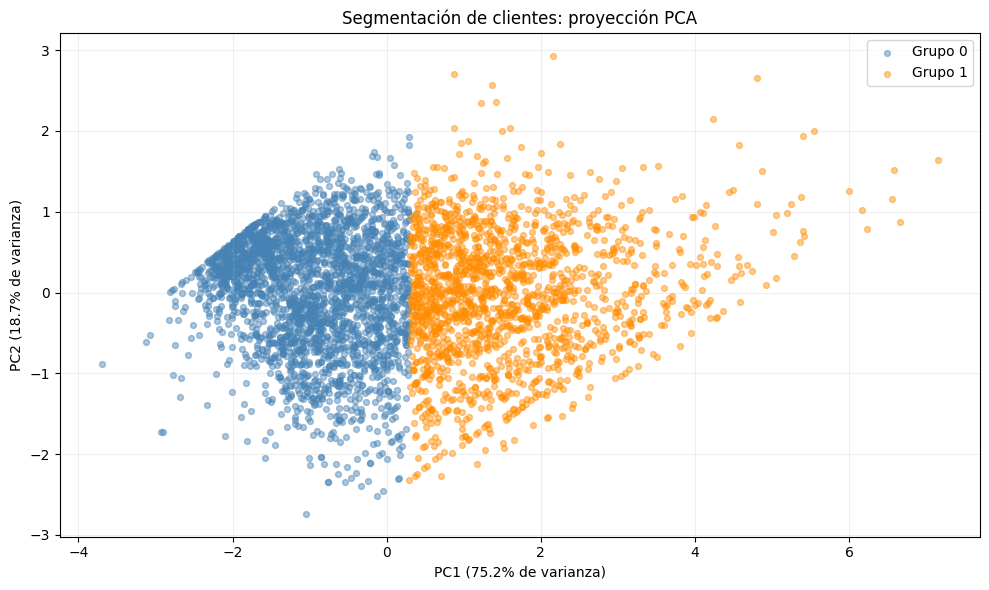

In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, svd_solver="full")

coordenadas = pca.fit_transform(rfm_escalado)

proyeccion = pd.DataFrame(
    coordenadas,
    index=rfm_escalado.index,
    columns=["PC1", "PC2"]
)

proyeccion["Grupo"] = clientes_segmentados["Grupo"]

varianza_explicada = pd.DataFrame({
    "Componente": ["PC1", "PC2"],
    "Varianza_explicada_pct": pca.explained_variance_ratio_ * 100
})

display(varianza_explicada.round(2))

varianza_total = pca.explained_variance_ratio_.sum() * 100
print(f"Varianza explicada por ambos componentes: {varianza_total:.2f}%")

fig, ax = plt.subplots(figsize=(10, 6))

for grupo, color in [(0, "steelblue"), (1, "darkorange")]:
    puntos = proyeccion[proyeccion["Grupo"] == grupo]

    ax.scatter(
        puntos["PC1"],
        puntos["PC2"],
        s=18,
        alpha=0.45,
        color=color,
        label=f"Grupo {grupo}"
    )

ax.set_title("Segmentación de clientes: proyección PCA")
ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% de varianza)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% de varianza)"
)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
fig.savefig("figures/segmentos_pca.png", dpi=160, bbox_inches="tight")
plt.show()

In [13]:
coeficientes_pca = pd.DataFrame(
    pca.components_.T,
    index=rfm_escalado.columns,
    columns=["PC1", "PC2"]
)

print("Coeficientes de las variables en cada componente:")
display(coeficientes_pca.round(3))

Coeficientes de las variables en cada componente:


,PC1,PC2
Recencia,-0.513,0.849
Frecuencia,0.617,0.264
Importe,0.597,0.457


### Interpretación de la proyección PCA

El primer componente explica el 75,17 % de la varianza y el segundo, el 18,68 %. Juntos conservan el 93,85 % de la variabilidad de las variables transformadas y estandarizadas.

PC1 combina negativamente la recencia y positivamente la frecuencia y el importe. Por tanto, valores elevados de este componente tienden a representar clientes con compras más recientes, frecuentes y de mayor importe acumulado.

PC2 tiene su mayor coeficiente en la recencia, aunque también incorpora frecuencia e importe. No debe interpretarse como una medida exclusiva del tiempo desde la última compra.

El grupo 1 se concentra hacia valores mayores de PC1, de acuerdo con su perfil de compras más recientes y frecuentes. El grupo 0 se concentra hacia valores menores.

La nube de puntos presenta continuidad entre los grupos. La frontera de colores refleja la partición realizada por K-means; no demuestra la existencia de dos categorías naturales claramente separadas.

El 6,15 % de la varianza queda fuera de esta representación. El porcentaje explicado describe la proyección y no es una medida de precisión del modelo.

## 12. Conclusiones y limitaciones

### Conclusiones

Construimos variables de recencia, frecuencia e importe para 4.334 clientes identificados.

La transformación logarítmica redujo la asimetría de las variables y la estandarización permitió trabajar con escalas comparables.

Entre las alternativas evaluadas, seleccionamos dos grupos por su mayor coeficiente de silueta, de 0,433, y por la sencillez de sus perfiles:

- El grupo 0 reúne al 61,68 % de los clientes. Presenta medianas de 97 días desde la última compra, una factura y £358,38 de importe acumulado.
- El grupo 1 reúne al 38,32 % de los clientes. Presenta medianas de 17 días, seis facturas y £2.044,87. Concentra el 84,88 % de las ventas positivas seleccionadas.

La asignación es muy estable frente a las diez semillas evaluadas, con un ARI mínimo de 0,9981.

La proyección PCA conserva el 93,85 % de la varianza y permite visualizar los perfiles, aunque muestra continuidad entre ellos.

### Limitaciones

Los importes acumulan ventas positivas sin descontar cancelaciones posteriores. No representan gasto neto, rentabilidad ni valor futuro del cliente.

Se excluyen registros sin identificación de cliente y se conservan filas repetidas cuya naturaleza no podemos confirmar.

Los clientes tienen distintos tiempos de seguimiento. Quienes aparecen cerca del cierre disponen de menos tiempo para acumular compras.

La segmentación depende de las variables, transformaciones, escalado y número de grupos elegidos. Las correlaciones entre frecuencia e importe también influyen en las distancias.

La estabilidad frente a semillas no demuestra estabilidad temporal ni robustez ante cambios en los datos.

Los segmentos son una descripción exploratoria. Su utilidad para campañas o decisiones comerciales requeriría validación adicional.

## 13. Exportación de resultados

Guardamos las variables RFM, las asignaciones, los perfiles y las métricas utilizadas para evaluar la segmentación.

También exportamos las coordenadas y los coeficientes de PCA para documentar la visualización. Los archivos conservan la precisión de cálculo; el redondeo se utiliza únicamente para presentar resultados.

In [14]:
from pathlib import Path

carpeta = Path("resultados")
carpeta.mkdir(exist_ok=True)

clientes_segmentados.to_csv(carpeta / "clientes_segmentados.csv")

evaluacion_k.to_csv(carpeta / "evaluacion_k.csv", index=False)
estabilidad.to_csv(carpeta / "estabilidad_semillas.csv", index=False)

for k, perfil in perfiles_comparados.items():
    perfil.to_csv(carpeta / f"perfiles_k{k}.csv")

proyeccion.to_csv(carpeta / "proyeccion_pca.csv")
varianza_explicada.to_csv(carpeta / "varianza_pca.csv", index=False)
coeficientes_pca.to_csv(
    carpeta / "coeficientes_pca.csv",
    index_label="Variable"
)

print("Resultados guardados en la carpeta resultados.")

Resultados guardados en la carpeta resultados.
